# 02 eda
# EDA 1 – Phân tích tín hiệu IMU theo thời gian

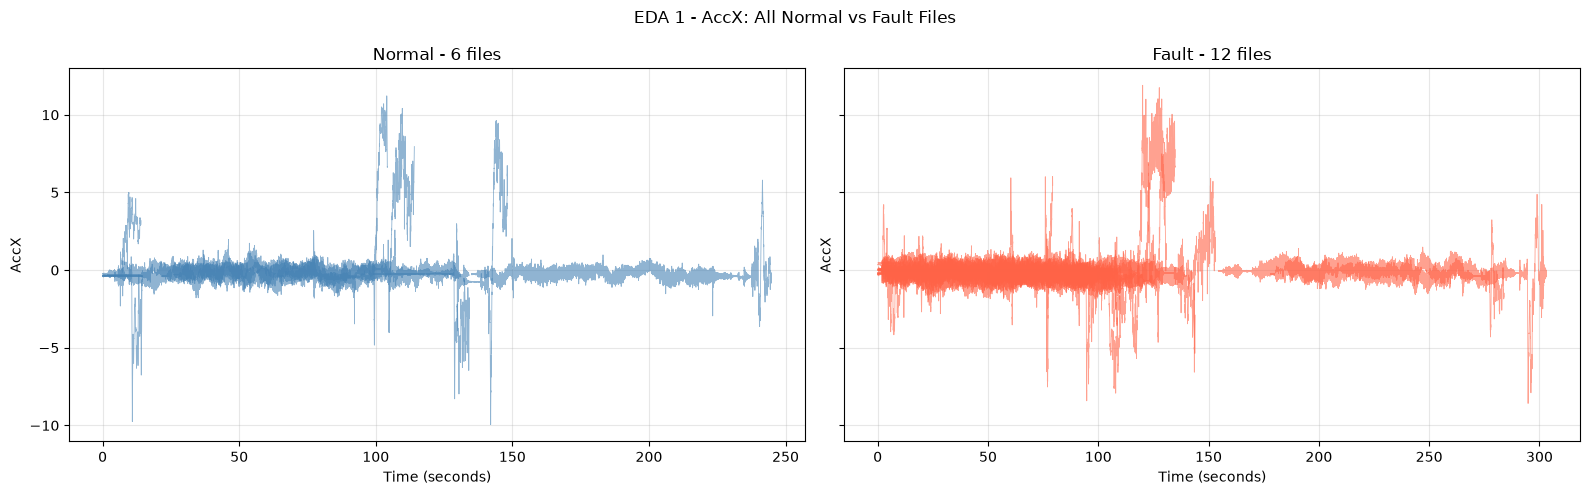

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Đọc dữ liệu đã gộp
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# Sắp xếp theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# Tách nhóm Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# Vẽ AccX của toàn bộ 18 file
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, (label, group, title, color) in zip(
    axes,
    [
        (0, normal, "Normal - 6 files", "steelblue"),
        (1, fault, "Fault - 12 files", "tomato")
    ]
):
    for file_name, data in group.groupby("source_file"):

        # Không nối đường qua khoảng trống thời gian lớn
        data = data.sort_values("Time_s").copy()
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "AccX"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["AccX"],
            linewidth=0.6,
            alpha=0.6,
            color=color
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("AccX")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - AccX: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


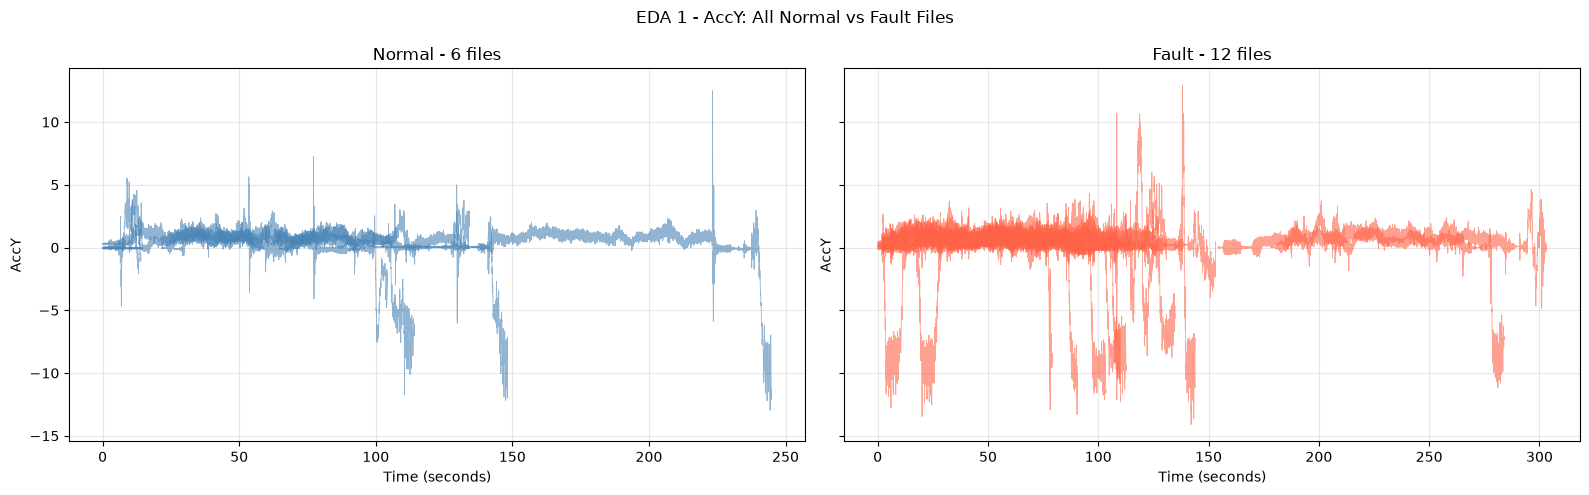

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp dữ liệu
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Tách hai nhóm
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ biểu đồ AccY
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, (group, title, color) in zip(
    axes,
    [
        (normal, "Normal - 6 files", "steelblue"),
        (fault, "Fault - 12 files", "tomato")
    ]
):
    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Ngắt đường khi có khoảng trống thời gian lớn
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "AccY"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["AccY"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("AccY")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - AccY: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


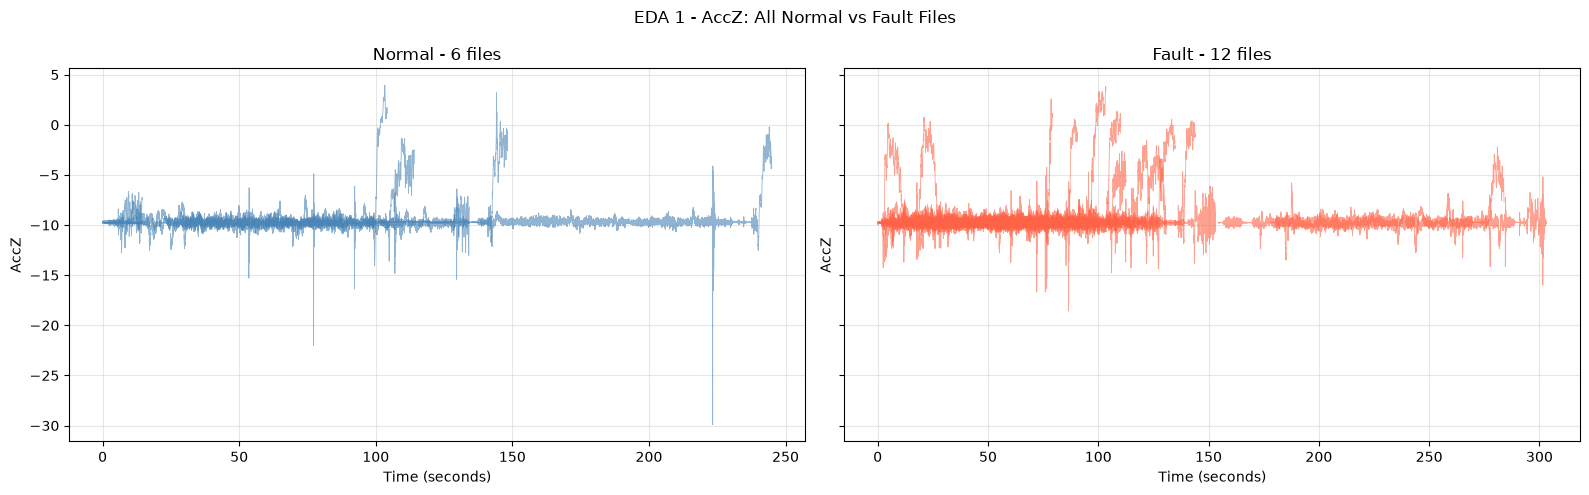

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu UAV
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp dữ liệu theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Tách Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ Line Chart AccZ
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Xác định khoảng trống thời gian lớn
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ qua khoảng trống lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "AccZ"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["AccZ"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("AccZ")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - AccZ: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


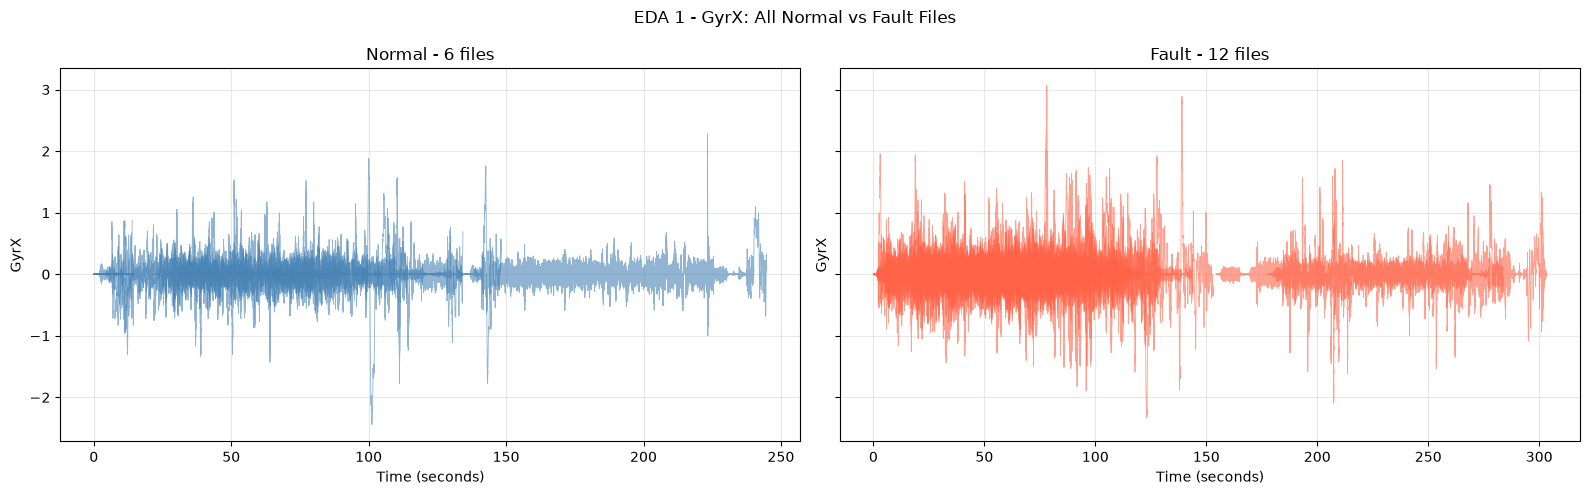

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Chia nhóm Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ biểu đồ GyrX
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Kiểm tra khoảng trống thời gian
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ nếu khoảng trống quá lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "GyrX"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["GyrX"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("GyrX")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - GyrX: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


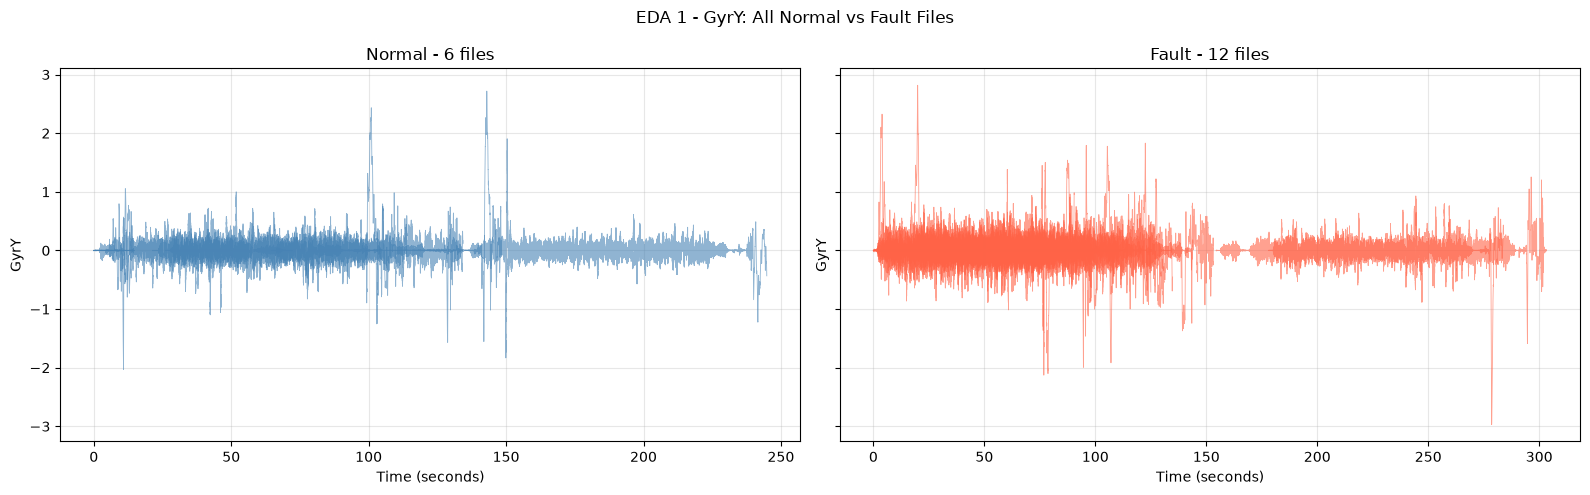

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp dữ liệu theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Chia thành hai nhóm
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ biểu đồ GyrY
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Tính khoảng cách giữa các mẫu đo
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ nếu có khoảng trống lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "GyrY"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["GyrY"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("GyrY")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - GyrY: All Normal vs Fault Files")
plt.tight_layout()
plt.show()


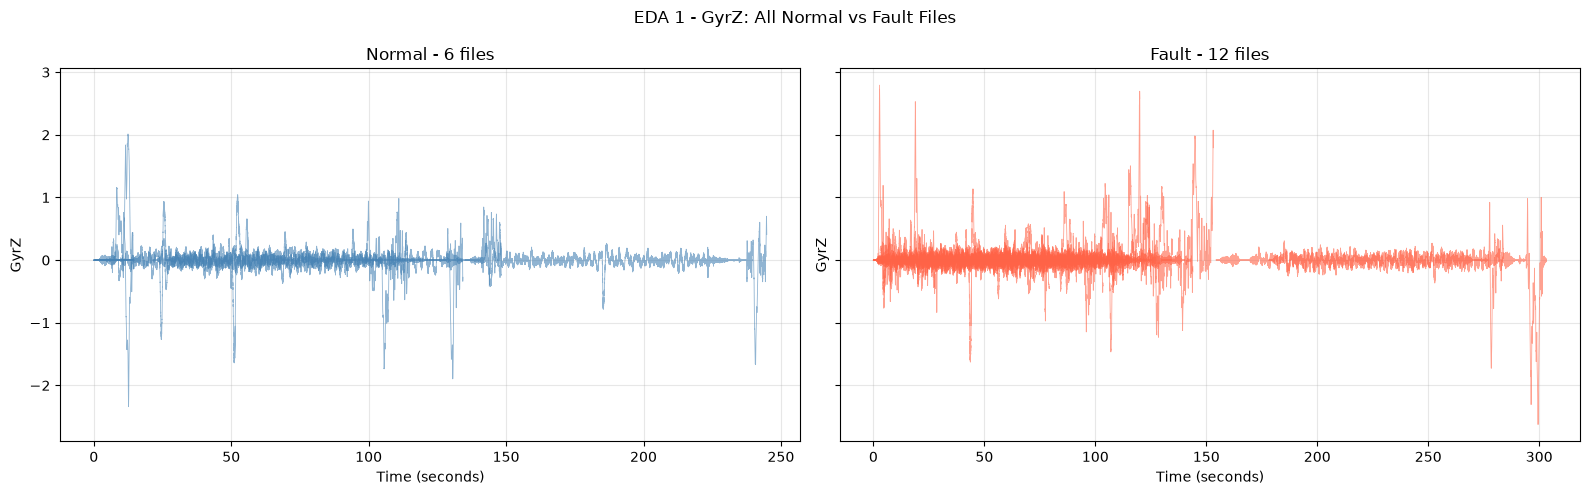

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu
df_uav = pd.read_csv("../data/processed/imu_combined.csv")

# 2. Sắp xếp theo file và thời gian
df_uav = df_uav.sort_values(
    ["source_file", "TimeUS"]
).copy()

# 3. Tính thời gian tương đối cho từng file
df_uav["Time_s"] = (
    df_uav["TimeUS"]
    - df_uav.groupby("source_file")["TimeUS"].transform("min")
) / 1_000_000

# 4. Tách nhóm Normal và Fault
normal = df_uav[df_uav["Label"] == 0]
fault = df_uav[df_uav["Label"] == 1]

# 5. Vẽ Line Chart GyrZ
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

groups = [
    (normal, "Normal - 6 files", "steelblue"),
    (fault, "Fault - 12 files", "tomato")
]

for ax, (group, title, color) in zip(axes, groups):

    for file_name, data in group.groupby("source_file"):

        data = data.sort_values("Time_s").copy()

        # Kiểm tra khoảng trống thời gian
        gaps = data["Time_s"].diff()
        typical_gap = gaps[gaps > 0].median()

        # Ngắt đường vẽ tại khoảng trống lớn
        if pd.notna(typical_gap):
            data.loc[
                gaps > 10 * typical_gap, "GyrZ"
            ] = np.nan

        ax.plot(
            data["Time_s"],
            data["GyrZ"],
            color=color,
            linewidth=0.6,
            alpha=0.6
        )

    ax.set_title(title)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("GyrZ")
    ax.grid(alpha=0.3)

plt.suptitle("EDA 1 - GyrZ: All Normal vs Fault Files")
plt.tight_layout()
plt.show()
